In [1]:
'''
trying a variable background subtracting
'''

'\ntrying a variable background subtracting\n'

In [6]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
# import scipy.ndimage as snm


import precision_recall as pr


# importlib.reload(plot_time_series)
import gc  # garbage collector
import glob  # i don't know if there is a better way to do this but this was the

# internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
# import implantation_functions as imp
# from tensorflow import keras
import get_postage_stamps as gpsf
import fitting

# from scipy.ndimage import sobel
# from scipy.signal import find_peaks
import importlib
import random
from pathlib import Path
import re


In [13]:
def get_row_background(row):
    """
    this function gets the background value of an array of various brightnesses
    and iteratively clips the maximum at a 3 standard deviation level to get the background value
    input: array of any dimensions
    return: background value (float)
    """

    change = 100
    newnorm = row
    while np.abs(change) > 0.0001:
        stdv = np.std(newnorm)
        norm_mean = np.mean(newnorm)
        newnorm = np.clip(
            newnorm, 0, norm_mean + 3 * stdv
        )  # check - is this the right cutoff
        newnorm_mean = np.mean(newnorm)
        change = newnorm_mean - norm_mean
        background = newnorm_mean
    return background

In [8]:
newimage = fits.open('/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/ztf_20221020294271_000449_zr_c16_x_0012.fits.fz')
testimage = newimage[2].dataanother

In [12]:
testimage.shape

(3080, 3072)

In [14]:
def get_image_background_by_row(image):
    """
    this function gets the background value of an array of various brightnesses
    and iteratively clips the maximum at a 3 standard deviation level to get the background value
    input: array of any dimensions
    return: background value (float)
    """
    bgs = np.zeros(image.shape[0])
    for i in range(image.shape[0]):
        row = image[i, :]
        rowbg = get_row_background(row)
        bgs[i]=rowbg
    return bgs

In [23]:
another = newimage[1].data

In [29]:
third = fits.open('/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/ztf_20221020148032_000686_zg_c05_x_0002.fits.fz')

In [30]:
thirdone = third[1].data

In [31]:
onebg = rff.get_image_background(thirdone)

In [32]:
onebg

170.17075

In [34]:
bgs = get_image_background_by_row(thirdone)

In [35]:
np.min(bgs), np.max(bgs)

(169.8571319580078, 170.48382568359375)

(array([3.310e+02, 2.246e+03, 5.000e+02, 2.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00]),
 array([270.43991089, 270.63340454, 270.82689819, 271.02039185,
        271.2138855 , 271.40737915, 271.6008728 , 271.79436646,
        271.98786011, 272.18135376, 272.37484741]),
 <BarContainer object of 10 artists>)

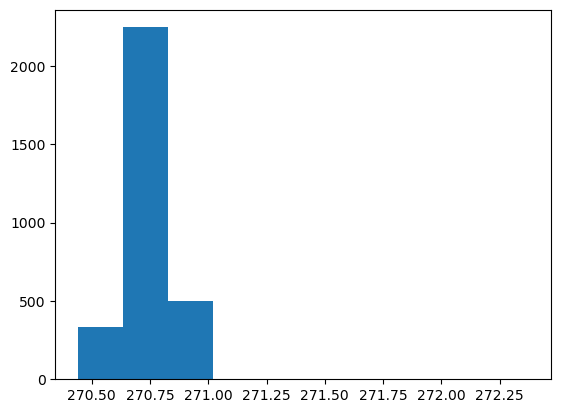

In [17]:
plt.hist(bgs)

In [40]:
def print_range_min_max(fname):
    path = '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/'
    file = fits.open(path+fname)
    image = file[1].data
    bgs = get_image_background_by_row(image)
    print(np.max(bgs)-np.min(bgs), np.min(bgs), np.max(bgs))

In [42]:
fnames = ['ztf_20221020148032_000686_zg_c05_x_0002.fits.fz',
          'ztf_20221020163819_000640_zg_c12_x_0001.fits.fz',
          'ztf_20221020297847_000449_zr_c04_x_0011.fits.fz',
          'ztf_20221020154120_000640_zi_c15_x_0028.fits.fz',
          'ztf_20221020294271_000449_zr_c16_x_0012.fits.fz',
          'ztf_20221020154120_000640_zi_c12_x_0028.fits.fz',
          'ztf_20221020138241_000686_zi_c16_x_0001.fits.fz',
          'ztf_20221020154120_000640_zi_c08_x_0014.fits.fz',
          'ztf_20221020148032_000686_zg_c16_x_0014.fits.fz',
           'ztf_20221020141806_000686_zi_c16_x_0020.fits.fz']
          
          
          
          
          
          
          
for fname in fnames:
    print(fname)
    print_range_min_max(fname)

ztf_20221020148032_000686_zg_c05_x_0002.fits.fz
0.6266937255859375 169.8571319580078 170.48382568359375
ztf_20221020163819_000640_zg_c12_x_0001.fits.fz
1.0833587646484375 190.22711181640625 191.3104705810547
ztf_20221020297847_000449_zr_c04_x_0011.fits.fz
1.052398681640625 204.5222930908203 205.57469177246094
ztf_20221020154120_000640_zi_c15_x_0028.fits.fz
2.306915283203125 189.7772674560547 192.0841827392578
ztf_20221020294271_000449_zr_c16_x_0012.fits.fz
1.860443115234375 190.52406311035156 192.38450622558594
ztf_20221020154120_000640_zi_c12_x_0028.fits.fz
2.064453125 228.3639373779297 230.4283905029297
ztf_20221020138241_000686_zi_c16_x_0001.fits.fz
2.1808624267578125 200.2239227294922 202.40478515625
ztf_20221020154120_000640_zi_c08_x_0014.fits.fz
1.2232208251953125 218.7148895263672 219.9381103515625
ztf_20221020148032_000686_zg_c16_x_0014.fits.fz
1.9527587890625 190.3549346923828 192.3076934814453
ztf_20221020141806_000686_zi_c16_x_0020.fits.fz
2.0573272705078125 199.824951171875